# 1. Final results on the held-out test sets

**What this notebook shows.** The answer to the task (`docs/TASK.md`): does the fused model —
three pathology foundation models (UNI2-h, Virchow2, GenBio-PathFM) plus age and sex — beat every
single model on held-out test patients, and how sure are we?

**How the numbers were made (in one paragraph).** The 203 patients were split 5 times (seeds 0–4)
into 162 development and 41 test patients, by patient and stratified by subtype. The agent chose
its designs on seed 0's development patients only. Three designs were then frozen. For each seed,
every model was trained once on the 162 development patients and predicted the 41 test patients
once. So every design has **5 test results**, one per test set.

**Nothing is retrained in sections 1–6**: they read the saved results in `artifacts/final/`.
Section 7 lets you re-run the evaluation yourself (one seed, or all five).

In [1]:
# Run from anywhere inside the repository: move to its root so every path below works.
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from src.eval import final_view as fv

fv.style()
pd.set_option("display.max_colwidth", 200)
print("Repository:", root.name)

Repository: lung-fm-fusion


In [2]:
runs = fv.load_final("artifacts/final")
primary = fv.primary(runs)
print(f"Seeds loaded: {sorted(runs)}   ·   designs: {fv.designs(runs)}   ·   primary design: {primary}")

Seeds loaded: [0, 1, 2, 3, 4]   ·   designs: ['H1', 'H2', 'C1']   ·   primary design: H1


## 2. The three frozen designs

All three train one tile-level model per foundation model (it reads 1,024 tiles of the slide and
learns which tiles matter), then multiply their predicted probabilities with a small age-and-sex
model. They differ in how each tile-level model is trained:

| Design | Tile-level model | Role |
| --- | --- | --- |
| **H1** | attention pooling + an extra training target (4 grade groups) | **primary**: the agent's own choice |
| H2 | CLAM (attention + pseudo-labelled tiles) + the grade-group target | highest development score |
| C1 | CLAM, without the grade-group target | best design without it |

The primary design was fixed *before* any test set was read, and is never changed afterwards.

In [3]:
fv.designs_table(runs)

,Candidate,Role,Test AUROC (mean ± sd),Test bal. acc. (mean ± sd),Development AUROC (mean ± sd)
Design,,,,,
H1,H1:raw,primary,0.894 ± 0.012,0.560 ± 0.045,0.863 ± 0.011
H2,H2:raw,secondary,0.894 ± 0.016,0.548 ± 0.058,0.865 ± 0.010
C1,C1:raw,secondary,0.891 ± 0.016,0.544 ± 0.051,0.862 ± 0.012


## 3. The required comparison table (TASK.md §5.3), primary design

Every row uses **the same tile-level recipe**, so the table isolates the effect of fusion
(TASK.md: "keep the downstream classifier family and tuning budget identical across rows").

- *Mean ± sd* is over the 5 test sets.
- *[95% CI]* is a bootstrap interval over the 41 patients of seed 0's test set (the headline split).

In [4]:
fv.task_table(runs, primary)

,Test macro AUROC (mean ± sd),Test balanced accuracy (mean ± sd),Seed 0 AUROC [95% CI],Seed 0 bal. acc. [95% CI]
Configuration,,,,
Age and sex only,0.594 ± 0.047,0.275 ± 0.031,"0.617 [0.514, 0.724]","0.262 [0.149, 0.381]"
UNI2-h alone,0.893 ± 0.013,0.549 ± 0.123,"0.909 [0.860, 0.948]","0.425 [0.307, 0.537]"
Virchow2 alone,0.881 ± 0.011,0.544 ± 0.051,"0.883 [0.835, 0.927]","0.493 [0.362, 0.623]"
GenBio-PathFM alone,0.884 ± 0.015,0.538 ± 0.062,"0.896 [0.845, 0.943]","0.463 [0.326, 0.590]"
Best single model + age and sex,0.895 ± 0.011,0.561 ± 0.099,"0.909 [0.858, 0.951]","0.419 [0.308, 0.524]"
Fused + age and sex,0.894 ± 0.012,0.560 ± 0.045,"0.908 [0.862, 0.945]","0.543 [0.426, 0.655]"


**For reference: the original rows 1–5** (each model's tiles simply averaged into one vector, then
logistic regression). These are weaker because averaging dilutes the tumour tiles with normal lung
and stroma.

In [5]:
fv.baseline_table(runs)

,Test macro AUROC (mean ± sd),Test balanced accuracy (mean ± sd)
Configuration,,
Age and sex only,0.594 ± 0.047,0.275 ± 0.031
UNI2-h alone,0.844 ± 0.032,0.487 ± 0.081
Virchow2 alone,0.831 ± 0.033,0.475 ± 0.109
GenBio-PathFM alone,0.844 ± 0.030,0.479 ± 0.060
Best single model + age and sex,0.835 ± 0.035,0.486 ± 0.062


## 4. Test AUROC on each of the 5 test sets

One dot per test set, with its 95% interval. Blue: the fused model. Orange: UNI2-h alone under
the same recipe (the strongest single model). Green: the original row 5.

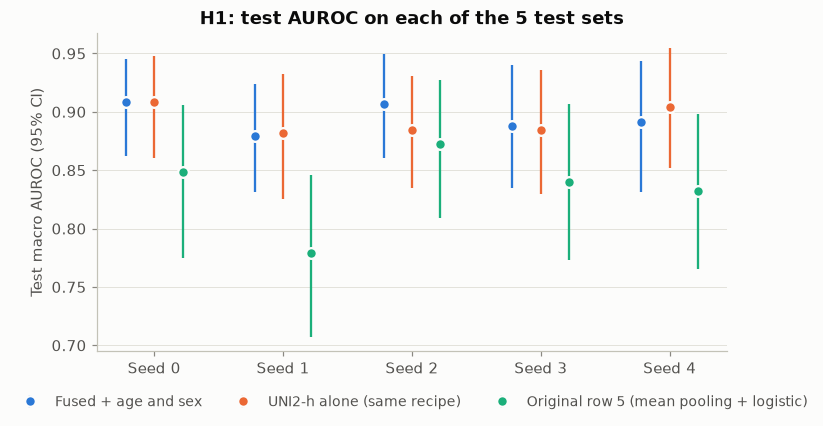

In [6]:
fv.plot_per_seed(runs, primary); plt.show()

## 5. Does the fused model beat each single model?

For each test set, the fused model's AUROC minus the other row's AUROC on the **same patients**
(a paired comparison). A row counts as *beaten on a seed* only if the 95% interval of that
difference lies entirely above 0 (rule fixed in advance in `conf/final.yaml`).

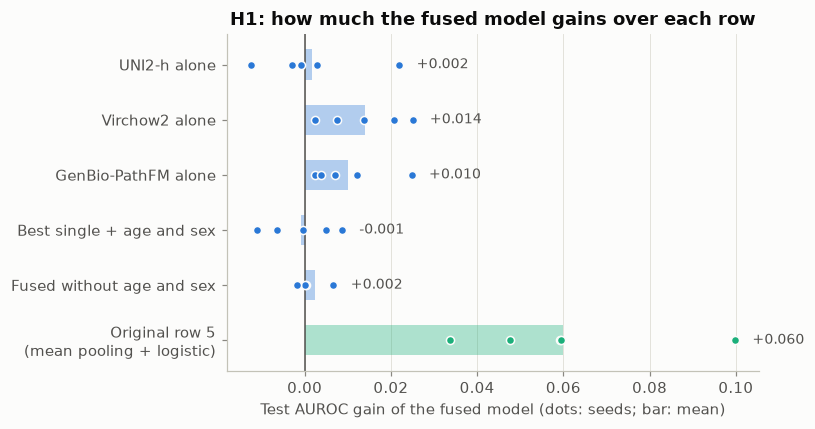

In [7]:
fv.plot_gains(runs, primary); plt.show()

In [8]:
fv.gain_table(runs, primary)

,Seed 0,Seed 1,Seed 2,Seed 3,Seed 4,Mean gain ± sd,Seeds with gain > 0,Seeds with CI > 0
Compared with,,,,,,,,
UNI2-h alone (same recipe),-0.001,-0.003,+0.022,+0.003,-0.012,+0.002 ± 0.013,2/5,0/5
Virchow2 alone (same recipe),+0.025,+0.008,+0.014,+0.021,+0.002,+0.014 ± 0.009,5/5,0/5
GenBio-PathFM alone (same recipe),+0.012,+0.002,+0.004,+0.007,+0.025,+0.010 ± 0.009,5/5,0/5
Best single model + age and sex (same recipe),-0.000,-0.006,+0.009,+0.005,-0.011,-0.001 ± 0.008,2/5,0/5
Fused without age and sex (same recipe),+0.000,-0.000,+0.007,+0.007,-0.002,+0.002 ± 0.004,3/5,0/5
Age and sex only (same recipe),+0.291,+0.236,+0.285,+0.347,+0.345,+0.301 ± 0.047,5/5,5/5
Age and sex only (original rows 1–5),+0.291,+0.236,+0.285,+0.347,+0.345,+0.301 ± 0.047,5/5,5/5
UNI2-h alone (original rows 1–5),+0.061,+0.085,+0.030,+0.051,+0.023,+0.050 ± 0.025,5/5,4/5
Virchow2 alone (original rows 1–5),+0.055,+0.101,+0.052,+0.069,+0.040,+0.063 ± 0.024,5/5,5/5


**How to read this.**
- Against the original rows 1–5, the fused model wins clearly on every test set (+0.05 to +0.06).
  That gain comes from the tile-level recipe.
- Against each model **under the same recipe**, the fused model is ahead of Virchow2 and
  GenBio-PathFM on all 5 test sets, but only level with UNI2-h; no interval lies above 0.
  Fusion matches the best single model; it does not clearly beat it.
- Age and sex add about +0.002.

## 6. Failure analysis

**Per class.** Each test set holds only 3–9 patients per class, so these are means over the 5 sets.

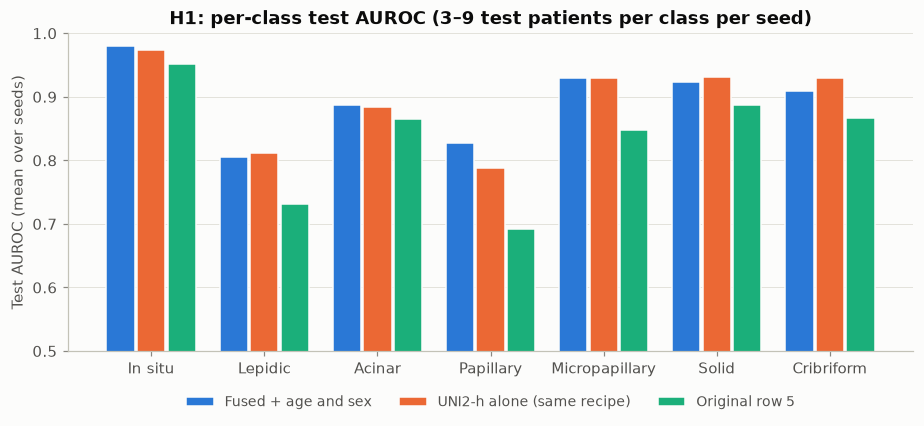

In [9]:
fv.plot_per_class(runs, primary); plt.show()

**Confusion matrix** (all 5 test sets added up; each patient appears once per test set it is in).
Colour is the share of the true class; numbers are patients. The weak spots are **Lepidic**
(mostly called Acinar or Papillary) and **Papillary** (often called Acinar): the low-grade patterns
that differ by how much of the tumour shows each architecture.

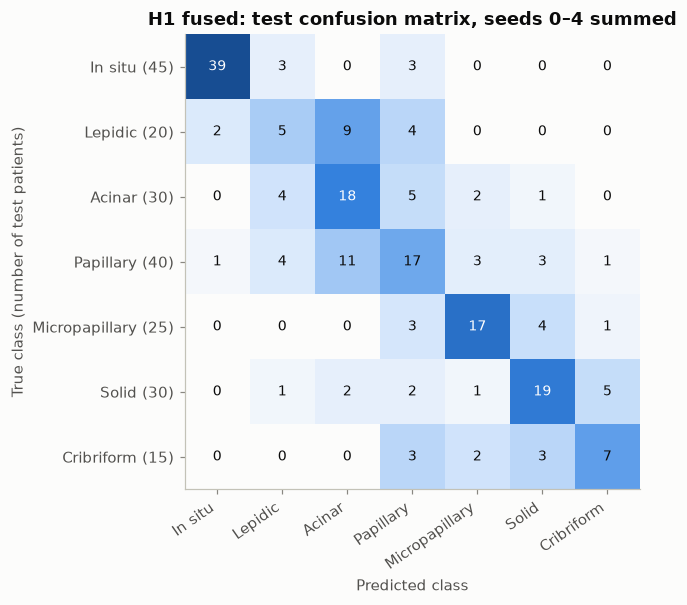

In [10]:
fv.plot_confusion(runs, primary); plt.show()

**Full tables** — every design, every row, per-seed intervals, development vs test and the
sensitivity analysis without the five patients with conflicting labels — are in `docs/results.md`:

In [11]:
display(Markdown(Path("docs/results.md").read_text()))

# Results: final evaluation on the held-out test sets

Seeds 0, 1, 2, 3, 4; per seed 162 development and 41 test patients, disjoint by patient. Code: 9af9cd7689. GPU: NVIDIA GeForce RTX 4090. Generated by `scripts/13_final_report.py` from `artifacts/final/seed_*/results.json`.

**Protocol.** The designs, the primary design, the rows and the claim rule were frozen in `conf/final.yaml` before any test set was read (decisions/SUMMARY.md). Per seed, each model is fitted once on all 162 development patients and predicts the 41 test patients once. Uncertainty: mean ± sd over the seeds, and per seed a 95% bootstrap CI over its test patients (2,000 class-stratified resamples). Every row under a design uses that design's own recipe (TASK.md §5.3: identical classifier family and budget); the original rows 1–5 (mean-pooled slide vectors + tuned logistic regression) are shown as a separate reference. Seed 0 is the headline split; seeds 1–4 are secondary (their development sets overlap seed 0's test set, on which the designs were not selected but whose development data guided the loop).

## H1 (H1:raw, primary, agent-selected): TASK.md §5.3 table

| Configuration | Test macro AUROC (mean ± sd) | Test balanced acc. (mean ± sd) | Seed 0 test AUROC [95% CI] | Seed 0 test bal. acc. [95% CI] | Dev AUROC (mean ± sd) |
| --- | --- | --- | --- | --- | --- |
| Metadata only (age + sex) | 0.594 ± 0.047 | 0.275 ± 0.031 | 0.617 [0.514, 0.724] | 0.262 [0.149, 0.381] | 0.611 ± 0.010 |
| UNI2-h alone | 0.893 ± 0.013 | 0.549 ± 0.123 | 0.909 [0.860, 0.948] | 0.425 [0.307, 0.537] | 0.858 ± 0.013 |
| Virchow2 alone | 0.881 ± 0.011 | 0.544 ± 0.051 | 0.883 [0.835, 0.927] | 0.493 [0.362, 0.623] | 0.845 ± 0.013 |
| GenBio-PathFM alone | 0.884 ± 0.015 | 0.538 ± 0.062 | 0.896 [0.845, 0.943] | 0.463 [0.326, 0.590] | 0.849 ± 0.011 |
| Best single model + metadata (UNI2-h, UNI2-h, UNI2-h, UNI2-h, UNI2-h) | 0.895 ± 0.011 | 0.561 ± 0.099 | 0.909 [0.858, 0.951] | 0.419 [0.308, 0.524] | 0.862 ± 0.013 |
| **Fused (agent-selected) + metadata** | 0.894 ± 0.012 | 0.560 ± 0.045 | 0.908 [0.862, 0.945] | 0.543 [0.426, 0.655] | 0.863 ± 0.011 |
| Fused without metadata (diagnostic) | 0.892 ± 0.012 | 0.566 ± 0.061 | 0.908 [0.861, 0.945] | 0.502 [0.374, 0.622] | 0.860 ± 0.012 |

**H1: fused vs each row on the test set** (paired bootstrap over the test patients; gain in macro AUROC [95% CI], share of resamples won). A row is beaten on a seed when the CI excludes 0.

| Fused vs | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 | Mean gain ± sd | Seeds gain > 0 | Seeds CI > 0 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| UNI2-h alone | -0.001 [-0.027, +0.025], 48% | -0.003 [-0.026, +0.020], 41% | +0.022 [-0.003, +0.049], 95% | +0.003 [-0.023, +0.028], 57% | -0.012 [-0.052, +0.018], 25% | +0.002 ± 0.013 | 2/5 | 0/5 |
| Virchow2 alone | +0.025 [-0.001, +0.052], 97% | +0.008 [-0.014, +0.029], 78% | +0.014 [-0.014, +0.039], 85% | +0.021 [-0.002, +0.049], 96% | +0.002 [-0.017, +0.023], 60% | +0.014 ± 0.009 | 5/5 | 0/5 |
| GenBio-PathFM alone | +0.012 [-0.017, +0.047], 78% | +0.002 [-0.029, +0.031], 56% | +0.004 [-0.011, +0.023], 65% | +0.007 [-0.026, +0.039], 69% | +0.025 [-0.002, +0.053], 96% | +0.010 ± 0.009 | 5/5 | 0/5 |
| Best single model + metadata | -0.000 [-0.028, +0.026], 48% | -0.006 [-0.025, +0.011], 26% | +0.009 [-0.013, +0.031], 77% | +0.005 [-0.017, +0.027], 66% | -0.011 [-0.045, +0.015], 25% | -0.001 ± 0.008 | 2/5 | 0/5 |
| Metadata only (age + sex) | +0.291 [+0.178, +0.405], 100% | +0.236 [+0.128, +0.352], 100% | +0.285 [+0.192, +0.379], 100% | +0.347 [+0.234, +0.461], 100% | +0.345 [+0.259, +0.440], 100% | +0.301 ± 0.047 | 5/5 | 5/5 |
| Fused without metadata (diagnostic) | +0.000 [-0.013, +0.014], 53% | -0.000 [-0.018, +0.017], 52% | +0.007 [-0.004, +0.021], 86% | +0.007 [-0.009, +0.024], 81% | -0.002 [-0.015, +0.009], 40% | +0.002 ± 0.004 | 3/5 | 0/5 |

## H2 (H2:raw, secondary): TASK.md §5.3 table

| Configuration | Test macro AUROC (mean ± sd) | Test balanced acc. (mean ± sd) | Seed 0 test AUROC [95% CI] | Seed 0 test bal. acc. [95% CI] | Dev AUROC (mean ± sd) |
| --- | --- | --- | --- | --- | --- |
| Metadata only (age + sex) | 0.594 ± 0.047 | 0.275 ± 0.031 | 0.617 [0.514, 0.724] | 0.262 [0.149, 0.381] | 0.611 ± 0.010 |
| UNI2-h alone | 0.894 ± 0.009 | 0.553 ± 0.130 | 0.904 [0.853, 0.945] | 0.421 [0.306, 0.526] | 0.859 ± 0.015 |
| Virchow2 alone | 0.890 ± 0.016 | 0.527 ± 0.051 | 0.912 [0.866, 0.951] | 0.461 [0.345, 0.577] | 0.850 ± 0.008 |
| GenBio-PathFM alone | 0.876 ± 0.026 | 0.557 ± 0.062 | 0.892 [0.847, 0.932] | 0.463 [0.326, 0.590] | 0.844 ± 0.015 |
| Best single model + metadata (Virchow2, UNI2-h, Virchow2, UNI2-h, UNI2-h) | 0.900 ± 0.014 | 0.575 ± 0.049 | 0.920 [0.880, 0.954] | 0.543 [0.425, 0.656] | 0.864 ± 0.013 |
| **Fused + metadata** | 0.894 ± 0.016 | 0.548 ± 0.058 | 0.915 [0.872, 0.951] | 0.479 [0.367, 0.596] | 0.865 ± 0.010 |
| Fused without metadata (diagnostic) | 0.894 ± 0.015 | 0.554 ± 0.046 | 0.916 [0.873, 0.952] | 0.520 [0.390, 0.643] | 0.861 ± 0.011 |

**H2: fused vs each row on the test set** (paired bootstrap over the test patients; gain in macro AUROC [95% CI], share of resamples won). A row is beaten on a seed when the CI excludes 0.

| Fused vs | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 | Mean gain ± sd | Seeds gain > 0 | Seeds CI > 0 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| UNI2-h alone | +0.011 [-0.013, +0.044], 79% | +0.004 [-0.019, +0.032], 62% | +0.015 [-0.004, +0.036], 94% | -0.003 [-0.028, +0.022], 40% | -0.026 [-0.071, +0.011], 10% | +0.000 ± 0.016 | 3/5 | 0/5 |
| Virchow2 alone | +0.003 [-0.016, +0.023], 60% | +0.005 [-0.018, +0.029], 67% | +0.008 [-0.015, +0.031], 77% | +0.018 [-0.007, +0.044], 92% | -0.011 [-0.048, +0.018], 29% | +0.005 ± 0.010 | 4/5 | 0/5 |
| GenBio-PathFM alone | +0.024 [-0.002, +0.056], 97% | +0.009 [-0.014, +0.032], 76% | +0.014 [-0.012, +0.044], 82% | +0.001 [-0.031, +0.036], 52% | +0.044 [+0.011, +0.079], 100% | +0.018 ± 0.017 | 5/5 | 1/5 |
| Best single model + metadata | -0.004 [-0.021, +0.010], 28% | -0.004 [-0.023, +0.018], 34% | +0.001 [-0.021, +0.021], 54% | +0.007 [-0.013, +0.030], 72% | -0.026 [-0.066, +0.006], 6% | -0.005 ± 0.012 | 2/5 | 0/5 |
| Metadata only (age + sex) | +0.298 [+0.189, +0.407], 100% | +0.241 [+0.137, +0.352], 100% | +0.285 [+0.191, +0.377], 100% | +0.350 [+0.245, +0.458], 100% | +0.329 [+0.235, +0.428], 100% | +0.301 ± 0.042 | 5/5 | 5/5 |
| Fused without metadata (diagnostic) | -0.000 [-0.014, +0.015], 47% | +0.002 [-0.015, +0.018], 60% | +0.002 [-0.011, +0.016], 66% | +0.011 [-0.007, +0.031], 88% | -0.014 [-0.037, +0.004], 7% | +0.000 ± 0.009 | 3/5 | 0/5 |

## C1 (C1:raw, secondary): TASK.md §5.3 table

| Configuration | Test macro AUROC (mean ± sd) | Test balanced acc. (mean ± sd) | Seed 0 test AUROC [95% CI] | Seed 0 test bal. acc. [95% CI] | Dev AUROC (mean ± sd) |
| --- | --- | --- | --- | --- | --- |
| Metadata only (age + sex) | 0.594 ± 0.047 | 0.275 ± 0.031 | 0.617 [0.514, 0.724] | 0.262 [0.149, 0.381] | 0.611 ± 0.010 |
| UNI2-h alone | 0.892 ± 0.005 | 0.524 ± 0.114 | 0.895 [0.840, 0.940] | 0.425 [0.321, 0.524] | 0.856 ± 0.015 |
| Virchow2 alone | 0.883 ± 0.011 | 0.544 ± 0.073 | 0.895 [0.850, 0.933] | 0.462 [0.356, 0.562] | 0.846 ± 0.012 |
| GenBio-PathFM alone | 0.877 ± 0.024 | 0.540 ± 0.049 | 0.901 [0.859, 0.938] | 0.463 [0.326, 0.590] | 0.839 ± 0.013 |
| Best single model + metadata (UNI2-h, UNI2-h, Virchow2, UNI2-h, UNI2-h) | 0.892 ± 0.006 | 0.549 ± 0.067 | 0.902 [0.849, 0.946] | 0.481 [0.367, 0.600] | 0.861 ± 0.013 |
| **Fused + metadata** | 0.891 ± 0.016 | 0.544 ± 0.051 | 0.910 [0.860, 0.950] | 0.479 [0.367, 0.596] | 0.862 ± 0.012 |
| Fused without metadata (diagnostic) | 0.892 ± 0.013 | 0.551 ± 0.052 | 0.914 [0.868, 0.951] | 0.485 [0.365, 0.604] | 0.856 ± 0.013 |

**C1: fused vs each row on the test set** (paired bootstrap over the test patients; gain in macro AUROC [95% CI], share of resamples won). A row is beaten on a seed when the CI excludes 0.

| Fused vs | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 | Mean gain ± sd | Seeds gain > 0 | Seeds CI > 0 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| UNI2-h alone | +0.014 [-0.006, +0.035], 92% | -0.001 [-0.026, +0.023], 48% | +0.015 [-0.012, +0.041], 86% | -0.001 [-0.021, +0.022], 46% | -0.031 [-0.079, +0.007], 6% | -0.001 ± 0.018 | 2/5 | 0/5 |
| Virchow2 alone | +0.015 [-0.005, +0.035], 92% | +0.008 [-0.016, +0.034], 73% | +0.017 [-0.013, +0.047], 87% | +0.023 [-0.004, +0.055], 95% | -0.022 [-0.057, +0.005], 7% | +0.008 ± 0.018 | 4/5 | 0/5 |
| GenBio-PathFM alone | +0.008 [-0.021, +0.038], 71% | +0.021 [-0.004, +0.050], 94% | +0.011 [-0.017, +0.044], 75% | +0.003 [-0.030, +0.042], 56% | +0.025 [-0.005, +0.056], 94% | +0.014 ± 0.009 | 5/5 | 0/5 |
| Best single model + metadata | +0.008 [-0.007, +0.025], 84% | +0.000 [-0.019, +0.022], 50% | +0.011 [-0.022, +0.040], 77% | +0.002 [-0.018, +0.020], 58% | -0.028 [-0.066, +0.001], 4% | -0.001 ± 0.015 | 4/5 | 0/5 |
| Metadata only (age + sex) | +0.292 [+0.185, +0.401], 100% | +0.244 [+0.136, +0.356], 100% | +0.279 [+0.184, +0.371], 100% | +0.349 [+0.242, +0.461], 100% | +0.320 [+0.228, +0.419], 100% | +0.297 ± 0.040 | 5/5 | 5/5 |
| Fused without metadata (diagnostic) | -0.005 [-0.019, +0.011], 29% | +0.006 [-0.012, +0.024], 77% | +0.008 [-0.005, +0.024], 88% | +0.002 [-0.016, +0.023], 58% | -0.019 [-0.044, +0.000], 3% | -0.001 ± 0.011 | 3/5 | 0/5 |

## Reference: the original rows 1–5 (mean-pooled slide vectors + tuned logistic regression)

| Configuration | Test macro AUROC (mean ± sd) | Test balanced acc. (mean ± sd) | Seed 0 test AUROC [95% CI] | Seed 0 test bal. acc. [95% CI] | Dev AUROC (mean ± sd) |
| --- | --- | --- | --- | --- | --- |
| Metadata only (age + sex) | 0.594 ± 0.047 | 0.275 ± 0.031 | 0.617 [0.514, 0.724] | 0.262 [0.149, 0.381] | 0.612 ± 0.016 |
| UNI2-h alone | 0.844 ± 0.032 | 0.487 ± 0.081 | 0.847 [0.774, 0.905] | 0.487 [0.363, 0.603] | 0.787 ± 0.020 |
| Virchow2 alone | 0.831 ± 0.033 | 0.475 ± 0.109 | 0.853 [0.787, 0.907] | 0.414 [0.288, 0.538] | 0.778 ± 0.020 |
| GenBio-PathFM alone | 0.844 ± 0.030 | 0.479 ± 0.060 | 0.863 [0.797, 0.919] | 0.471 [0.329, 0.602] | 0.779 ± 0.013 |
| Best single model + metadata (UNI2-h, Virchow2, GenBio-PathFM, UNI2-h, GenBio-PathFM) | 0.835 ± 0.035 | 0.486 ± 0.062 | 0.849 [0.775, 0.906] | 0.503 [0.380, 0.614] | 0.792 ± 0.017 |

**Each design's fused model vs the original rows** (test AUROC gain, mean ± sd over seeds; seeds with the paired CI above 0).

| Design | Metadata only (age + sex) | UNI2-h alone | Virchow2 alone | GenBio-PathFM alone | Best single model + metadata |
| --- | --- | --- | --- | --- | --- |
| H1 | +0.301 ± 0.047 (5/5) | +0.050 ± 0.025 (4/5) | +0.063 ± 0.024 (5/5) | +0.051 ± 0.020 (5/5) | +0.060 ± 0.025 (5/5) |
| H2 | +0.301 ± 0.042 (5/5) | +0.050 ± 0.033 (3/5) | +0.063 ± 0.030 (4/5) | +0.051 ± 0.021 (4/5) | +0.060 ± 0.028 (4/5) |
| C1 | +0.297 ± 0.040 (5/5) | +0.046 ± 0.037 (3/5) | +0.060 ± 0.035 (4/5) | +0.047 ± 0.025 (3/5) | +0.056 ± 0.032 (4/5) |

## Per-seed test macro AUROC (H1; [95% CI] over that seed's 41 test patients)

| Configuration | Seed 0 | Seed 1 | Seed 2 | Seed 3 | Seed 4 |
| --- | --- | --- | --- | --- | --- |
| Metadata only (age + sex) | 0.617 [0.514, 0.724] | 0.643 [0.539, 0.739] | 0.621 [0.541, 0.701] | 0.541 [0.425, 0.651] | 0.546 [0.428, 0.647] |
| UNI2-h alone | 0.909 [0.860, 0.948] | 0.882 [0.825, 0.932] | 0.884 [0.835, 0.931] | 0.885 [0.830, 0.935] | 0.904 [0.852, 0.955] |
| Virchow2 alone | 0.883 [0.835, 0.927] | 0.871 [0.815, 0.924] | 0.892 [0.845, 0.939] | 0.867 [0.808, 0.924] | 0.889 [0.831, 0.942] |
| GenBio-PathFM alone | 0.896 [0.845, 0.943] | 0.877 [0.827, 0.921] | 0.902 [0.849, 0.952] | 0.880 [0.829, 0.931] | 0.867 [0.794, 0.934] |
| Best single model + metadata | 0.909 [0.858, 0.951] | 0.885 [0.832, 0.934] | 0.898 [0.851, 0.940] | 0.883 [0.826, 0.940] | 0.902 [0.853, 0.951] |
| **Fused (agent-selected) + metadata** | 0.908 [0.862, 0.945] | 0.879 [0.832, 0.924] | 0.906 [0.860, 0.950] | 0.888 [0.835, 0.940] | 0.891 [0.832, 0.944] |
| Fused without metadata (diagnostic) | 0.908 [0.861, 0.945] | 0.879 [0.826, 0.931] | 0.900 [0.854, 0.945] | 0.881 [0.829, 0.932] | 0.893 [0.837, 0.945] |
| Row 5, original (mean pooling + logistic) | 0.849 [0.775, 0.906] | 0.779 [0.707, 0.846] | 0.873 [0.809, 0.927] | 0.840 [0.773, 0.907] | 0.832 [0.766, 0.898] |

## Per-class test AUROC (H1, mean over seeds)

Each test set holds 3–9 patients per class (Cribriform 3, Lepidic 4), so per-class values are noisy.

| Row | In situ | Lepidic | Acinar | Papillary | Micropapillary | Solid | Cribriform |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Fused (agent-selected) + metadata | 0.981 | 0.805 | 0.887 | 0.828 | 0.929 | 0.923 | 0.909 |
| Fused without metadata (diagnostic) | 0.979 | 0.807 | 0.892 | 0.814 | 0.928 | 0.917 | 0.907 |
| UNI2-h alone | 0.974 | 0.812 | 0.884 | 0.788 | 0.930 | 0.931 | 0.930 |
| Virchow2 alone | 0.975 | 0.789 | 0.866 | 0.810 | 0.934 | 0.891 | 0.898 |
| GenBio-PathFM alone | 0.968 | 0.808 | 0.898 | 0.810 | 0.907 | 0.909 | 0.891 |
| Best single model + metadata | 0.978 | 0.799 | 0.884 | 0.798 | 0.933 | 0.936 | 0.939 |
| Row 5 (original: mean pooling + logistic) | 0.952 | 0.731 | 0.866 | 0.692 | 0.848 | 0.887 | 0.867 |

## Confusion matrix (H1 fused, test, summed over seeds 0, 1, 2, 3, 4)

Rows: true class; columns: predicted class (argmax). Per-class recall in the last column.

| True \ Predicted | In situ | Lepidic | Acinar | Papillary | Micropapillary | Solid | Cribriform | Recall |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| In situ | 39 | 3 | 0 | 3 | 0 | 0 | 0 | 0.87 |
| Lepidic | 2 | 5 | 9 | 4 | 0 | 0 | 0 | 0.25 |
| Acinar | 0 | 4 | 18 | 5 | 2 | 1 | 0 | 0.60 |
| Papillary | 1 | 4 | 11 | 17 | 3 | 3 | 1 | 0.42 |
| Micropapillary | 0 | 0 | 0 | 3 | 17 | 4 | 1 | 0.68 |
| Solid | 0 | 1 | 2 | 2 | 1 | 19 | 5 | 0.63 |
| Cribriform | 0 | 0 | 0 | 3 | 2 | 3 | 7 | 0.47 |

Seed 0 alone (41 patients): diagonal 25/41 correct; rows In situ 9/9; Lepidic 2/4; Acinar 1/6; Papillary 4/8; Micropapillary 4/5; Solid 5/6; Cribriform 0/3.

## Development vs test (selection optimism)

| Design | Dev AUROC (mean ± sd) | Test AUROC (mean ± sd) | Test − dev (mean) | Seed 0: dev → test |
| --- | --- | --- | --- | --- |
| H1 | 0.863 ± 0.011 | 0.894 ± 0.012 | +0.031 | 0.863 → 0.908 |
| H2 | 0.865 ± 0.010 | 0.894 ± 0.016 | +0.029 | 0.866 → 0.915 |
| C1 | 0.862 ± 0.012 | 0.891 ± 0.016 | +0.029 | 0.861 → 0.910 |

## D11 sensitivity: test without the five patients with conflicting labels

| Design | Seeds with any of them in test | Test AUROC, all (mean) | Test AUROC, without them (mean) | Test bal. acc., all | Test bal. acc., without |
| --- | --- | --- | --- | --- | --- |
| H1 | 3/5 (s0: 2, s1: 0, s2: 2, s3: 2, s4: 0) | 0.894 | 0.897 | 0.560 | 0.564 |
| H2 | 3/5 (s0: 2, s1: 0, s2: 2, s3: 2, s4: 0) | 0.894 | 0.897 | 0.548 | 0.552 |
| C1 | 3/5 (s0: 2, s1: 0, s2: 2, s3: 2, s4: 0) | 0.891 | 0.894 | 0.544 | 0.548 |



## 7. Re-run the evaluation yourself

This trains every model of the three designs again and predicts the test patients again. It needs
the cached tile embeddings (`artifacts/features/`) and a CUDA GPU; our results used an NVIDIA RTX
4090 (other GPUs may differ in the last digits). Results go to `artifacts/final_rerun/`, so the committed results are **never overwritten**,
and the last cell checks that the re-run reproduces them exactly (the training is deterministic).

**Option A — one seed (default, about 13 minutes on one GPU).**

In [12]:
fv.run_final_eval([0], devices=("cuda:0",), out_dir="artifacts/final_rerun")

[  0.0 min] seed 0 started on cuda:0


[ 17.9 min] seed 0 done


-> artifacts/final_rerun/results.md, artifacts/final_rerun/summary.csv


**Option B — all five seeds (about 40 minutes on two GPUs).** Remove the `#` to run it. Seeds run
one per GPU at a time (one seed needs about 10 GB of GPU memory at its peak).

In [13]:
# fv.run_final_eval([0, 1, 2, 3, 4], devices=("cuda:0", "cuda:1"), out_dir="artifacts/final_rerun")

**Check:** the re-run against the committed results (largest difference over every score; 0 means identical).

In [14]:
rerun = fv.load_final("artifacts/final_rerun")
fv.compare_runs(rerun, runs)

,Numbers compared,Largest difference
Seed,,
0,94,0.0
